Upload the content image and style image:


Saving content.jpg to content.jpg
Images loaded successfully!
Style transfer model loaded successfully!


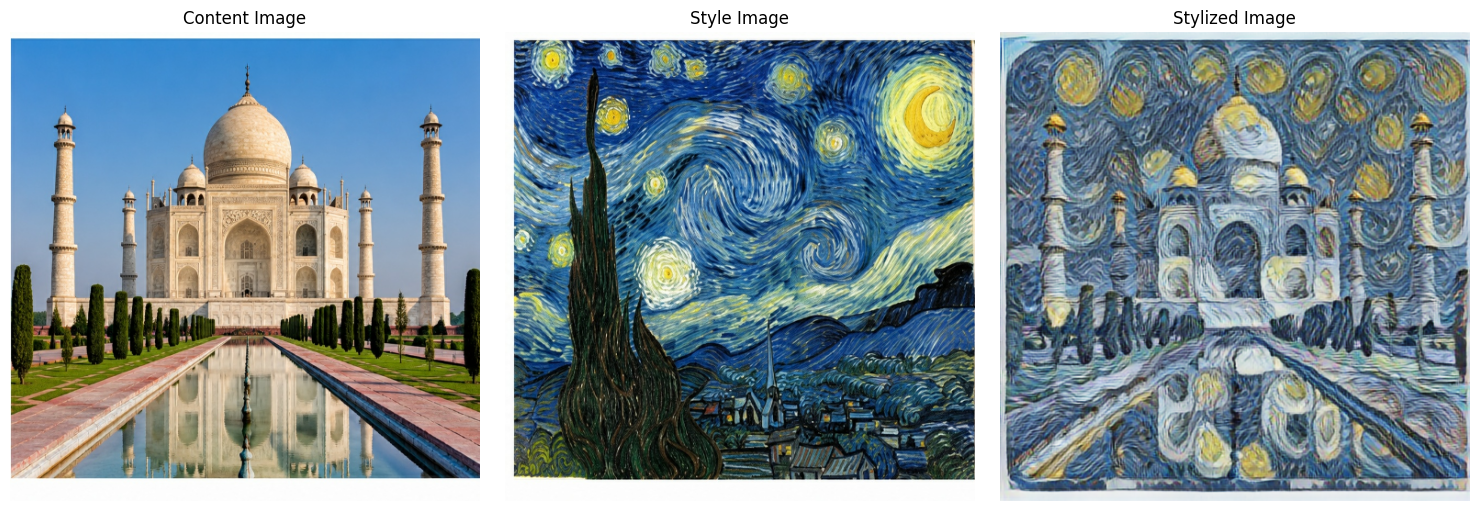

Stylized image saved successfully!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Neural Style Transfer completed successfully.


In [2]:
# Experiment No. 11
# Neural Style Transfer using TensorFlow

# 1. Import required libraries
import tensorflow as tf
import tensorflow_hub as hub
import matplotlib.pyplot as plt
from google.colab import files

# 2. Upload content and style images
print("Upload the content image and style image:")
uploaded = files.upload()

# Use these exact filenames when uploading
content_path = "/content/content.jpg"
style_path = "/content/style.jpg"

# 3. Load and preprocess image
def load_image(path):
    img = tf.io.read_file(path)
    img = tf.image.decode_image(
        img,
        channels=3,
        expand_animations=False
    )
    img = tf.image.convert_image_dtype(
        img,
        tf.float32
    )

    img = tf.image.resize(img, (512, 512))
    img = img[tf.newaxis, :]

    return img

# 4. Load both images
content_image = load_image(content_path)
style_image = load_image(style_path)

print("Images loaded successfully!")

# 5. Load pretrained Neural Style Transfer model
model = hub.load(
    "https://tfhub.dev/google/magenta/arbitrary-image-stylization-v1-256/2"
)

print("Style transfer model loaded successfully!")

# 6. Apply Neural Style Transfer
stylized_image = model(
    tf.constant(content_image),
    tf.constant(style_image)
)[0]

# 7. Display results
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(content_image[0])
plt.title("Content Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(style_image[0])
plt.title("Style Image")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(tf.clip_by_value(stylized_image[0], 0, 1))
plt.title("Stylized Image")
plt.axis("off")

plt.tight_layout()
plt.show()

# 8. Save generated image
output_path = "/content/stylized_image.png"

output_image = tf.clip_by_value(
    stylized_image[0], 0, 1
)

output_image = tf.image.convert_image_dtype(
    output_image, tf.uint8, saturate=True
)

tf.io.write_file(
    output_path,
    tf.image.encode_png(output_image)
)

print("Stylized image saved successfully!")

# 9. Download generated image
files.download(output_path)

# 10. Result
print("Neural Style Transfer completed successfully.")